Linnea Conradsson Sjöberg
LICO22

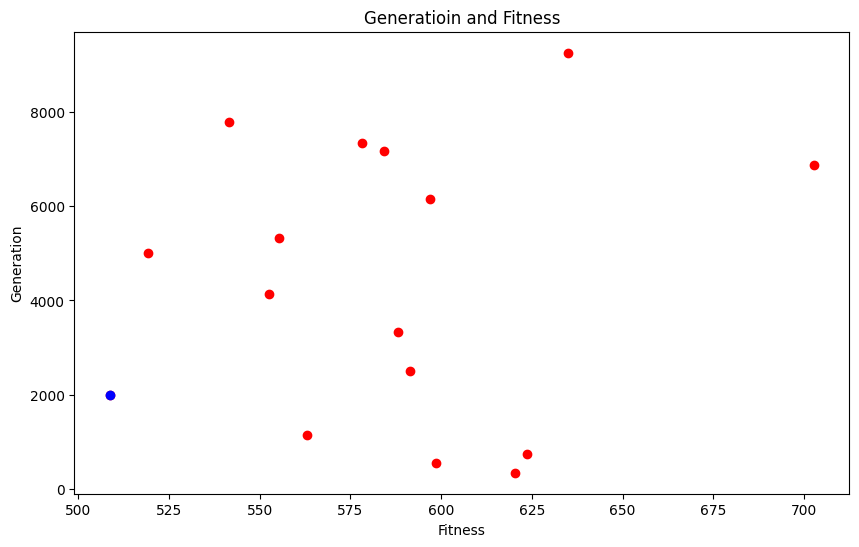

In [102]:
import matplotlib.pyplot as plt
"""
Plotting the restults from the GA code Task1.
"""

fitness = [598.6194592760226, 555.4548306772276, 552.6209120195858, 508.68024448337763, 
            519.2010189354896, 584.2253014359379, 634.8630260772958, 541.4595514877219,
            596.7938328883174, 578.216992455605, 623.6734136854669, 563.0838720420923, 
            620.4495908130397,  591.3909105084906, 588.2372131656269,  702.7452142696757]

generation = [535, 5337, 4136, 1996, 5006, 7170, 9266, 7785, 6162, 7341, 727, 1143, 338,
              2502, 3337, 6870]


plt.figure(figsize=(10, 6))

best = min(fitness)
for i in fitness:
    if i == best:
        index = fitness.index(i)
        plt.scatter(fitness, generation, color='red')
        plt.scatter(fitness[index], generation[index], color='blue')


plt.title('Generatioin and Fitness')
plt.xlabel('Fitness')
plt.ylabel('Generation')
plt.show()

In [2]:
# Task 3 
# Genetic Algorithm
"""
Genetic Algorithm for finding the best path in a maze
"""

import numpy as np
import random
import math


def fitness(x, y, z):
    math1 = (2 * x * z * (math.exp(-x)) - 2 * y**3 + y**2 - 3 * z**3)
    math2 = ((math.cos(x*z))/(1 + math.exp(-(x + y))))
    return math1 + math2


def population(size, bounds):
    population = []
    for _ in range(size):
        individual = {
            'x': np.random.uniform(*bounds['x']),
            'y': np.random.uniform(*bounds['y']),
            'z': np.random.uniform(*bounds['z'])
        }
        population.append(individual)

    fittness = []
    for individual in population:
        fit = fitness(individual['x'], individual['y'], individual['z'])
        fittness.append(fit)

    return population, fittness


def parents(population, fitnessValues):
    fitnessValues = np.array(fitnessValues)
    fitnessValues = np.maximum(fitnessValues, 0)
    totalFitness = fitnessValues.sum()

    if totalFitness <= 0:
        print("Total Fitness is 0 or negativ. Randomly selected parent.")
        return random.sample(population, len(population))
    

    probability = fitnessValues / totalFitness 
    indices = np.arange(len(population))
    parents = np.random.choice(indices, size=len(population), p=probability)
    
    return [population[i] for i in parents]


def crossover(parent1, parent2, crossover):
    alpha = random.random()

    if random.random() < crossover:  # crossover rate

        child1 = {
            'x': alpha * parent1['x'] + (1 - alpha) * parent2['x'],
            'y': alpha * parent1['y'] + (1 - alpha) * parent2['y'],
            'z': alpha * parent1['z'] + (1 - alpha) * parent2['z']
        }
        child2 = {
            'x': (1 - alpha) * parent1['x'] + alpha * parent2['x'],
            'y': (1 - alpha) * parent1['y'] + alpha * parent2['y'],
            'z': (1 - alpha) * parent1['z'] + alpha * parent2['z']
        }
        return child1, child2
    else:
        return parent1, parent2


def mutation(individual, bounds, mutation):
    if random.random() < mutation:
        genes = random.choice(['x', 'y', 'z'])
        individual[genes] = random.uniform(*bounds[genes])

    return individual


def geneticAlgorithm(size, generations, mrate, crossovers):
    bounds = {'x': (0, 5), 'y': (1, 10), 'z': (-2, 4)}


    for generation in range(generations):
        pop = population(size, bounds)
        populaition = pop[0]
        fittness = pop[1]
        parent = parents(populaition, fittness)

        newPopulation = []
        for i in range(0, size, 2):
            parent1, parent2 = parent[i], parent[i + 1]
            child1, child2 = crossover(parent1, parent2, crossovers)

            newPopulation.append(mutation(child1, bounds, mrate))
            newPopulation.append(mutation(child2, bounds, mrate))

        populaition = newPopulation

        bestIndiv = max(populaition, key=lambda ind: fitness(ind['x'], ind['y'], ind['z']))
        bestFit = fitness(bestIndiv['x'], bestIndiv['y'], bestIndiv['z'])

        print(f"Generation {generation + 1}: Best Fitness = {bestFit:.4f}, x = {bestIndiv['x']:.4f}, y = {bestIndiv['y']:.4f}, z = {bestIndiv['z']:.4f}")

    return bestIndiv


def main():
    size = 100
    generations = 50
    mutation = 0.9
    crossover = 0.7


    matrix = [
        [1,1,1,1,1,1,1,1,1,1,1,1,1000,1,1,1,1,1,1,1,1000,1,1,1,1,1,1,1,1,1,1,1000,1,1,1,1,1],
        [1000,1000,1000,1000,1000,1000,1,1000,1000,1000,1000,1,1000,1000,1,1000,1000,1000,1000,1,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1,1000,1,1000,1,1000,1000],
        [1,1,1,1,1,1,1,1000,1,1,1000,1,1000,1,1,1000,1000,1,1000,1,1,1,1,1,1000,1,1,1,1,1,1,1000,1,1000,1,1,1],
        [1,1000,1000,1000,1000,1000,1000,1000,1,1000,1000,1,1000,1,1000,1000,1000,1000,1,1000,1000,1000,1000,1,1000,1,1000,1000,1000,1000,1000,1000,1,1000,1000,1000,1],
        [1,1,1,1,1,1000,1,1,1,1,1000,1,1,1,1000,1000,1000,1,1,1,1,1,1,1,1000,1,1000,1,1,1,1,1,1,1,1,1000,1],
        [1000,1000,1000,1000,1,1000,1000,1,1000,1000,1000,1000,1000,1000,1000,1000,1000,1,1000,1000,1000,1000,1000,1000,1000,1,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1],
        [1,1,1,1000,1,1,1000,1,1,1,1,1,1,1,1,1,1000,1,1000,1,1,1,1,1,1000,1,1,1,1,1,1,1,1,1,1,1,1],
        [1,1000,1,1000,1000,1,1000,1000,1000,1000,1000,1000,1000,1000,1000,1,1000,1,1000,1,1000,1000,1000,1,1000,1000,1000,1000,1000,1000,1000,1000,1,1000,1000,1000,1000],
        [1,1000,1,1,1,1,1000,1,1,1,1000,1,1,1,1000,1,1000,1,1000,1,1000,1,1,1,1000,1,1,1,1000,1,1,1,1,1000,1,1,1],
        [1,1000,1000,1000,1000,1000,1000,1,1000,1,1000,1,1000,1,1000,1,1000,1,1000,1,1000,1,1000,1,1000,1,1000,1,1000,1,1000,1000,1,1000,1,1000,1],
        [1,1000,1,1,1,1,1000,1,1000,1,1,1,1000,1,1000,1,1,1,1000,1,1000,1,1000,1,1,1,1000,1,1000,1,1,1000,1,1,1,1000,1],
        [1,1000,1,1000,1000,1,1000,1,1000,1000,1000,1000,1000,1,1000,1000,1000,1000,1000,1,1000,1,1000,1000,1000,1000,1000,1,1000,1000,1000,1000,1,1000,1000,1000,1],
        [1,1000,1,1,1000,1,1,1,1000,1,1,1,1,1,1,1,1,1,1,1,1000,1,1,1,1,1,1000,1,1,1,1,1,1,1000,1,1,1]]

    geneticAlgorithm(size, generations, mutation, crossover)


if __name__ == "__main__":
    main()


Generation 1: Best Fitness = 3.7893, x = 4.5317, y = 1.7001, z = -1.4933
Total Fitness is 0 or negativ. Randomly selected parent.
Generation 2: Best Fitness = 11.9552, x = 0.4402, y = 1.1656, z = -1.6750
Generation 3: Best Fitness = 11.0430, x = 3.0588, y = 1.5496, z = -1.7472
Generation 4: Best Fitness = 12.8717, x = 3.7830, y = 1.8909, z = -1.9646
Generation 5: Best Fitness = 16.3960, x = 3.5049, y = 1.7176, z = -1.9776
Generation 6: Best Fitness = 2.5202, x = 0.0798, y = 1.0291, z = -1.0044
Generation 7: Best Fitness = 18.5945, x = 3.2710, y = 1.5775, z = -1.9854
Generation 8: Best Fitness = 9.4040, x = 0.2985, y = 1.8038, z = -1.8147
Generation 9: Best Fitness = 11.1148, x = 2.5885, y = 2.0001, z = -1.9854
Generation 10: Best Fitness = 12.7817, x = 2.9247, y = 1.6536, z = -1.8512
Generation 11: Best Fitness = 3.1183, x = 3.6921, y = 1.3827, z = -1.3029
Generation 12: Best Fitness = 17.7770, x = 4.5557, y = 1.3322, z = -1.9349
Generation 13: Best Fitness = 11.7629, x = 3.6778, y = 1

In [76]:
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import mean_squared_error


In [77]:
x_data = np.linspace(-0.5, 0.5, 200)[:, np.newaxis]
noise = np.random.normal(0, 0.02, x_data.shape)
y_data = np.square(x_data) + noise

x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.2, random_state=0)


In [78]:

linear = LinearRegression()
linear.fit(x_train, y_train)

y_predict_train = linear.predict(x_train)
y_predict_test = linear.predict(x_test)


mean_train = mean_squared_error(y_train, y_predict_train)
mean_test = mean_squared_error(y_test, y_predict_test)

print(mean_train)
print(mean_test)

print(f'Linear model Train time: {mean_train:.4f}')
print(f'Linear model Test time: {mean_test:.4f}')


0.006299662966833755
0.006131138913512777
Linear Model Train: 0.0063
Linear Model Test: 0.0061


In [79]:

pipeline = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
pipeline.fit(x_train, y_train)

y_predict_train = pipeline.predict(x_train)
y_predict_test = pipeline.predict(x_test)

polynom_train = mean_squared_error(y_train, y_predict_train)
polynom_test = mean_squared_error(y_test, y_predict_test)

print(polynom_train)
print(polynom_test)

print(f'Polynomial model train time: {polynom_train:.4f}')
print(f'Polynomial model test time: {polynom_test:.4f}')


0.00034138521549656686
0.00038480105547912026
Polynomial Model Train: 0.0003
Polynomial Model Test: 0.0004


In [80]:
neural_network = Sequential([
    Dense(6, activation='relu', input_shape=(1,)), 
    Dense(1)  
])

neural_network.compile(optimizer='adam', loss='mean_squared_error')
neural_network.fit(x_train, y_train, epochs=200, verbose=0)

y_nntrain = neural_network.predict(x_train)
y_nntest = neural_network.predict(x_test)

train = mean_squared_error(y_train, y_nntrain)
test = mean_squared_error(y_test, y_nntest)

print(train)
print(test)


print(f'Neural Network model train time: {train:.4f}')
print(f'Neural Network model test time: {test:.4f}')



2/2 [==============================] - 0s 3ms/step
Neural Network Model Train: 0.0008
Neural Network Model Test: 0.0007
0.0007672220302128481
0.0007239043992621293


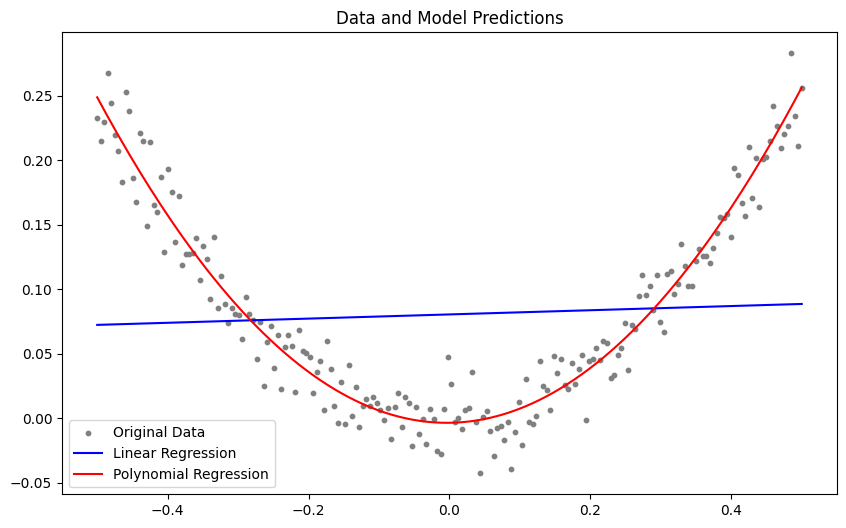

In [110]:

plt.figure(figsize=(10, 6))
plt.scatter(x_data, y_data, label='Original Data', color='gray', s=10)

plt.plot(x_data, linear.predict(x_data), label='Linear Regression', color='blue')

plt.plot(x_data, pipeline.predict(x_data), label='Polynomial Regression', color='red')

plt.title('Data and Model Predictions')
plt.legend()
plt.show()
